In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
sns.set_theme(style="whitegrid")

from qss.solver_options import brent_defaults
from qss.chemical_potential import chemical_potential
from qss.distributions import DistType, prepare_2D_lattice_data
import tools.scientific_plot_v2 as sp
plotter = sp.ScientificPlotter()

In [2]:
MU_B  = 1# eV/T
N = 100
t = -1
# t_prim = 0.25
t_prim = 0

kx = np.linspace(-np.pi, np.pi, N, endpoint=False)
ky = np.linspace(-np.pi, np.pi, N, endpoint=False)
e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

In [3]:
# Band filling values
n_min = 0.01
n_max = 0.999
n_count = 40

# Magnetic field values
Ha_min = -3
Ha_max = 3
Ha_count = 50

# Beta values

beta_min =-2
beta_max = 2
beta_count = 5

distros = [DistType.FD, DistType.FLB, DistType.NFL, DistType.NFLB, DistType.SSL]  # ND
n  = np.array([ 0.8, 0.9], dtype=np.float64)  # NN
n  = np.linspace(n_min, n_max, n_count, dtype=np.float64)  # NN
# beta = np.array([0.1, 1.0], dtype=np.float64)  # NB
beta = np.logspace(beta_min, beta_max, beta_count, dtype=np.float64)  # NB
H_a = np.array([0.0], dtype=np.float64) # NH
# H_a = np.logspace(Ha_min, Ha_max, Ha_count, dtype=np.float64) # NH
# H_a = np.concat([np.array([0.8]), H_a])

In [4]:
# n =np.array([0.01] + [0.025 + 0.025 * x for x in range(39)] + [0.99])
# beta= list(np.logspace(-2,3,61))
# beta.append(0.2)
# beta.append(np.inf)
# beta = np.sort(beta)
# beta = np.round(beta, 4)

In [5]:
py_opts = brent_defaults(
    abs_tol=1e-9, 
    rel_tol=1e-6, 
    expand_factor=2.0,
    initial_step=1.0,  
    max_expands=164,
    max_iters=5000      
)
native_opts= py_opts.to_qss()

In [6]:
mu = Path("chemical_potential_results00.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    beta = 1/k_BT
    H_a = np.unique(mu_df["H_a"])
    mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])

else:
    mu_df = chemical_potential(
        distros=distros,
        n_vals=n,
        beta_vals=beta,
        H_a_vals=H_a,
        N=N,
        E=e_k,
        solver_opts=native_opts,
        x0=-1.0,
        a0=-5.0,
        b0=5.0,
    )
    k_BT = 1/beta
    mu_df.to_csv("chemical_potential_results.csv")
mu_df

mu  iterations  converged      residual
distro n        k_BT   H_a                                                 
FD     0.010000 100.00 0.0 -529.350200          20       True  8.137874e-09
       0.035359 100.00 0.0 -401.770506          23       True  1.583139e-08
       0.060718 100.00 0.0 -346.402267          23       True  6.254147e-08
       0.086077 100.00 0.0 -310.185179          22       True  1.685919e-09
       0.111436 100.00 0.0 -283.029968          23       True  6.264613e-08
...                                ...         ...        ...           ...
SSL    0.897564 0.01   0.0    2.810296          17       True  5.297233e-08
       0.922923 0.01   0.0    3.077111          23       True  2.783862e-08
       0.948282 0.01   0.0    3.366265          23       True  8.989371e-08
       0.973641 0.01   0.0    3.668974          23       True  4.617714e-08
       0.999000 0.01   0.0    3.983881          25       True  5.561068e-08

[1000 rows x 4 columns]

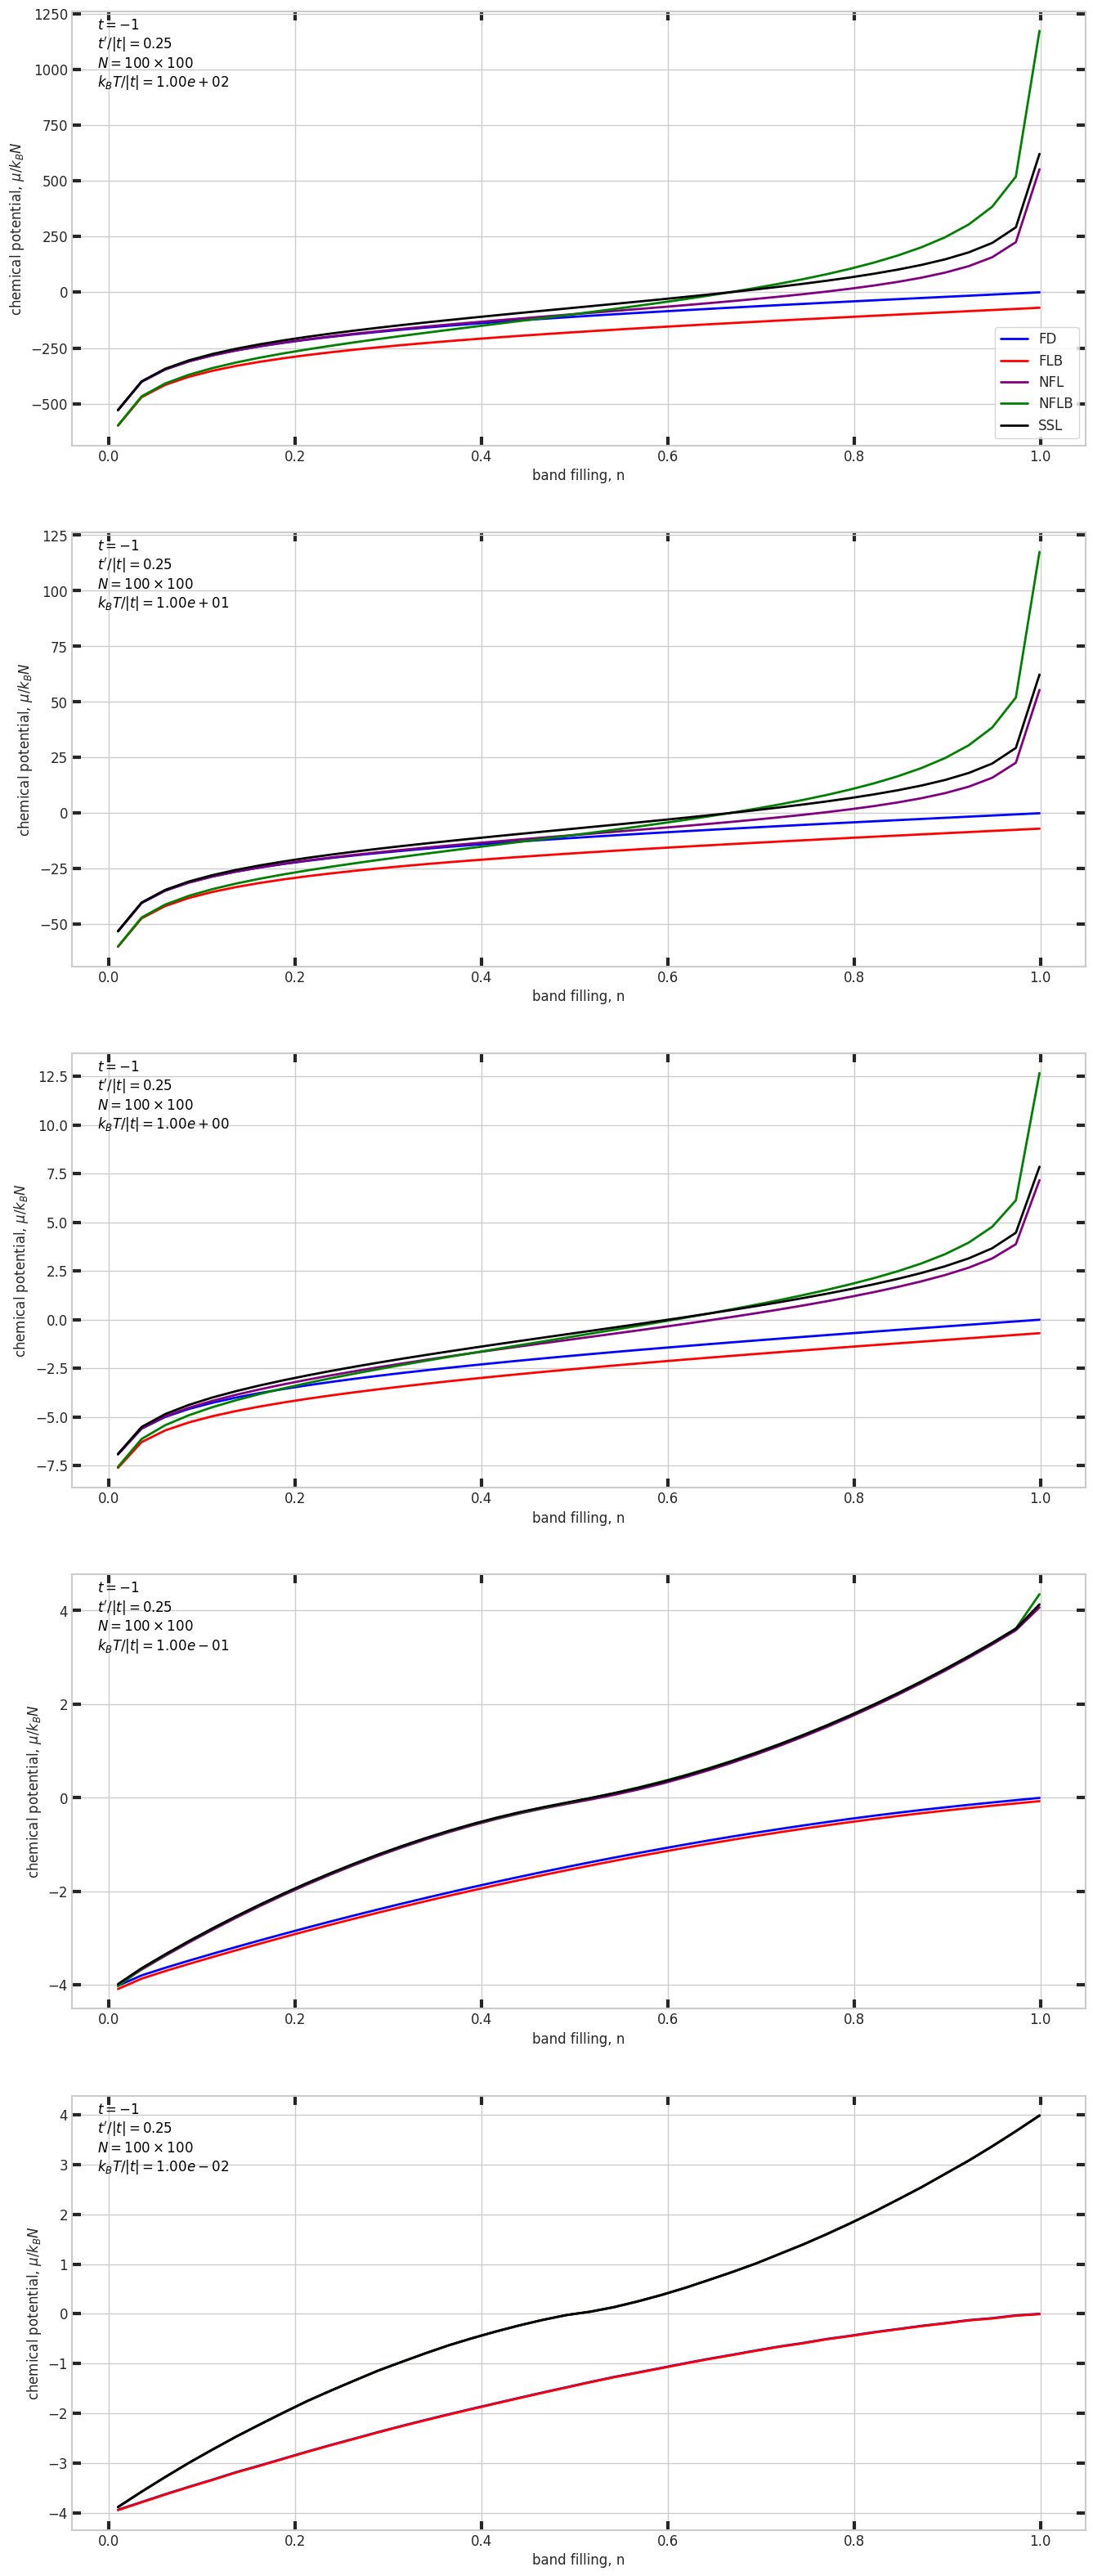

In [7]:
# Select a magnetic field to plot
H_a_plot = H_a[0]
beta_plot = beta

# Plot
plotter.plot_scalar_result(
    results=mu_df,
    x_param="n",
    y_col="mu",
    y_label=r"chemical potential, $\mu / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=[d.name for d in distros],
    subplots_param="beta",
    subplots_vals=beta_plot,
    cols=1,
    figsize=(16, 8)
)
plt.show()

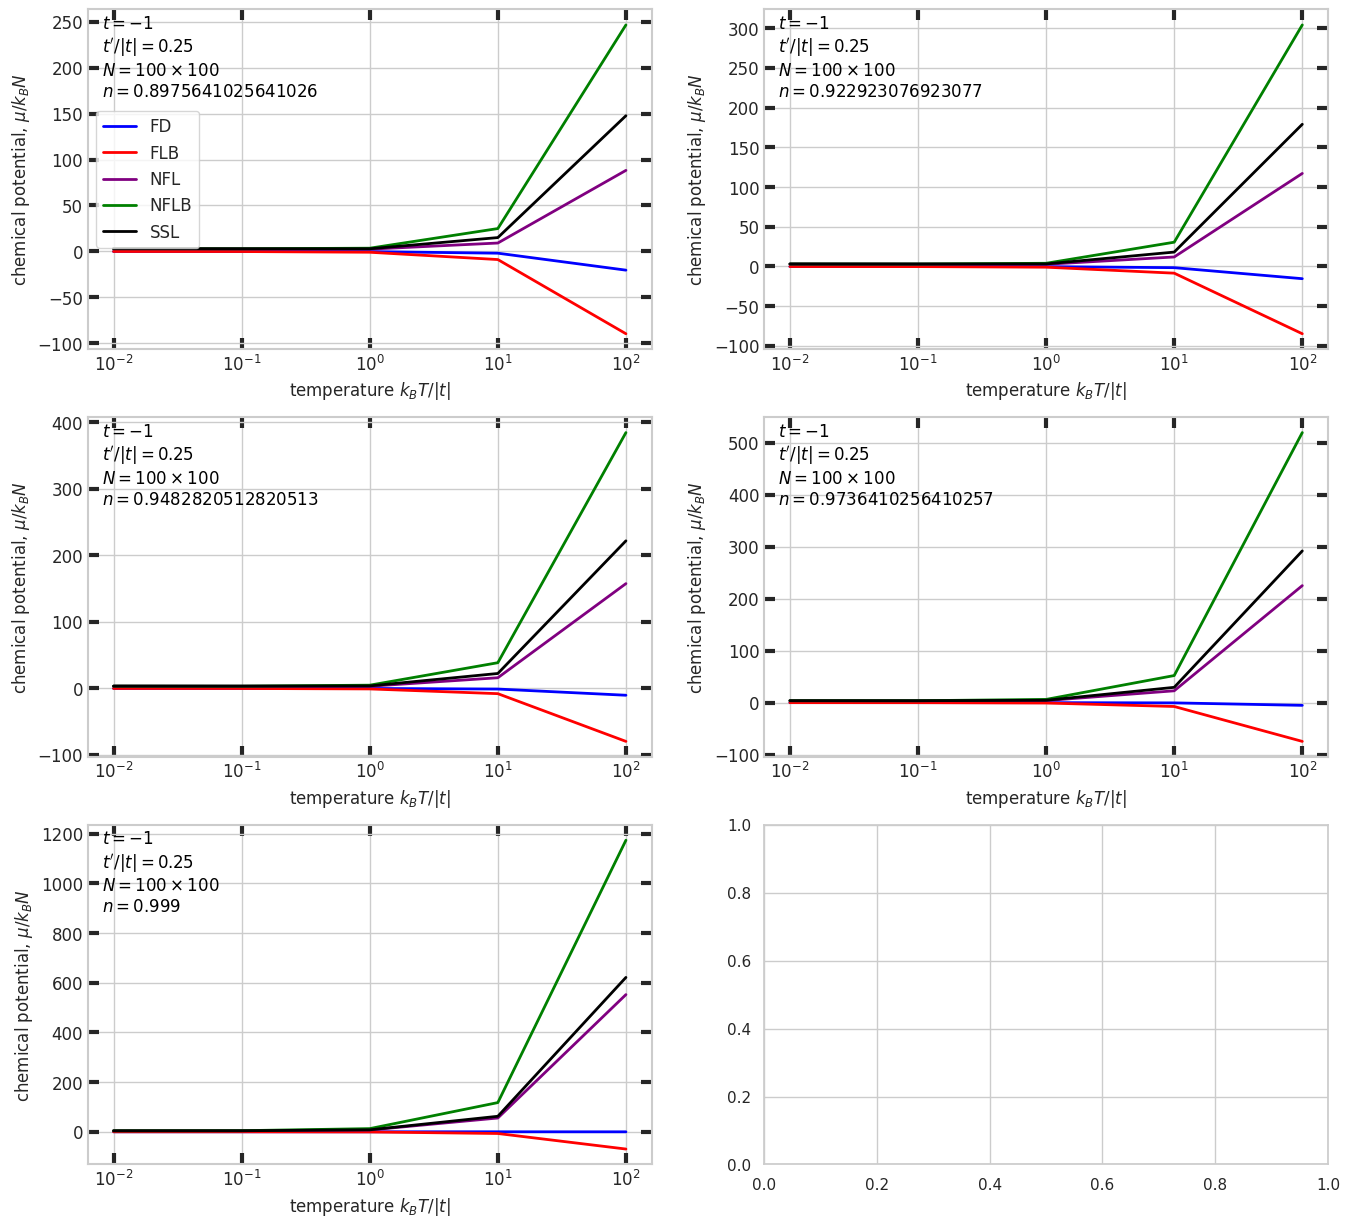

In [8]:
n_plot = n[-5:]
H_a_plot = H_a[0]

# Plot
plotter.plot_scalar_result(
    results=mu_df,
    x_param="k_BT",
    y_col="mu",
    y_label=r"chemical potential, $\mu / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=[d.name for d in distros],
    subplots_param="n",
    subplots_vals=n_plot,
    cols=2,
    figsize=(8, 5),
    xscale="log"
)
plt.show()

/home/mateuszzx/Workspace/Python_Workspace/Spalek_Workspace/quantum-statistics-solver/tools/scientific_plot_v2.py:92: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_xscale(xscale)


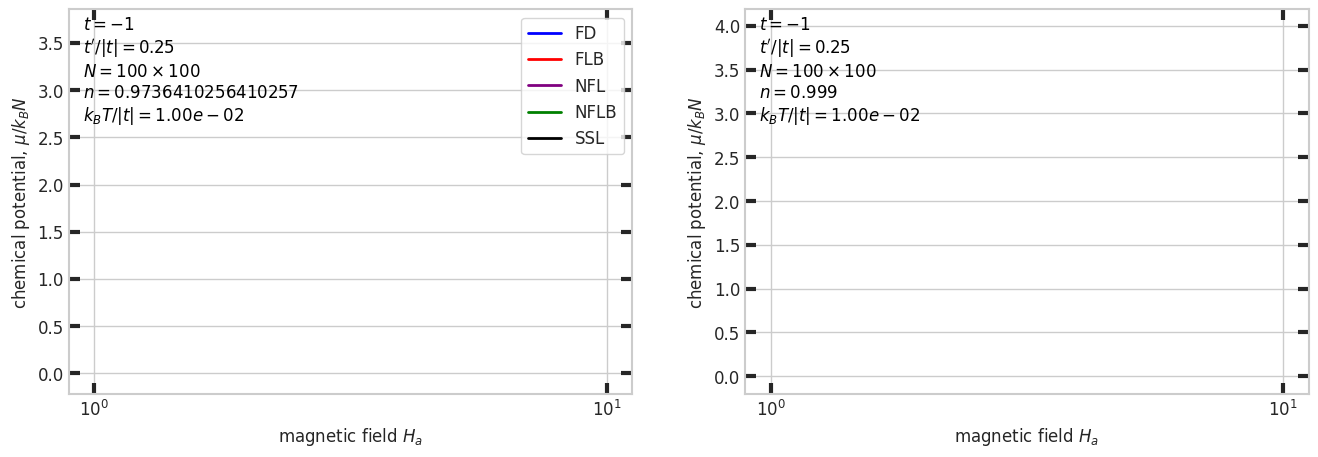

In [11]:
n_plot = n[-2:]
beta_plot = beta[0]
plotter.plot_scalar_result(
    results=mu_df,
    x_param="H_a",
    y_col="mu",
    y_label=r"chemical potential, $\mu / k_B N$",
    fixed_params={"beta": beta[-1]},
    distros=[d.name for d in distros],
    subplots_param="n",
    subplots_vals=n_plot,
    cols=2,
    figsize=(8, 5),
    xscale="log"
)
plt.show()

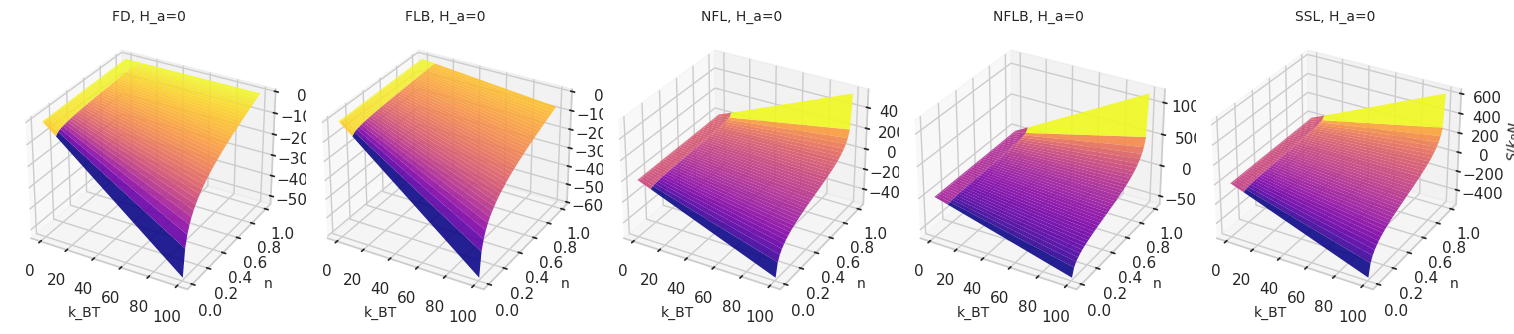

In [10]:
# Example: Plot Entropy vs Temperature (k_BT) and Magnetic Field (H_a)
# for different band fillings (n)

# Select a few n values for the rows
n_rows = [n[0], n[len(n)//2]] 
plotter.plot_3d_results(
    results=mu_df,
    row_param="H_a",       # Vary n across rows
    row_vals=H_a[:2],     # Specific n values
    x_param="k_BT",      # X axis
    y_param="n",       # Y axis
    z_label=r"$S / k_B N$",
    z_col="mu",          # or "entropy" if you have calculated it
    distros=[d.name for d in distros],
    # figsize=(15, 10)
)
plt.show()